# Actividad Integradora — Unidad 2
## Inferencia Estadística y Toma de Decisiones en Ingeniería
### Caso A: Arquitectura de Software (Monolito vs. Microservicios)

**Tecnológico Nacional de México — Instituto Tecnológico de Zacatepec**
Departamento de Sistemas y Computación · Ingeniería en Sistemas Computacionales
**Asignatura:** Fundamentos de Ciencia de Datos · **Docente:** Celia Ramos Palencia · **Grupo:** XB

**Equipo:**
- Muñoz García Jorge (23091000)
- Suárez Degante Luis Ángel (23091050)
- Hermosa Praxedis Carlos Rafael (23090958)
- Morantes Pereida Denzel Yahir (23090999)

---

**Objetivo.** Determinar, con evidencia estadística, si la sobrecarga de red que introduce una arquitectura de microservicios **incrementa la latencia de respuesta HTTP** respecto a un monolito que ejecuta exactamente la misma lógica de negocio.

| Elemento | Definición |
|---|---|
| Variable cuantitativa ($Y$) | `latencia_ms`: latencia extremo a extremo de una petición HTTP, en milisegundos |
| Variable cualitativa ($X$) | `grupo`: tipo de arquitectura (`Monolito` / `Microservicios`) |
| Unidad de observación | Una petición `GET /pedido` (consulta de usuario + inventario + precio) |

## 0. Origen de los datos: prueba de carga local (extracción directa)

En lugar de datos sintéticos, el dataset se obtuvo con una **prueba de carga controlada** sobre dos implementaciones reales (fuente permitida #2 de la actividad: *telemetría de pruebas de carga locales*). Todo el experimento está en un solo script, **`src/prueba_carga.py`** (solo biblioteca estándar):

- Implementa dos arquitecturas con la **misma lógica de negocio** (validación de usuario, cálculo de inventario y de precio):
  - **Monolito** (`:8000`): un proceso; los tres módulos se llaman como funciones en memoria.
  - **Microservicios**: un *API Gateway* (`:8100`) que orquesta por HTTP/JSON tres servicios independientes —`usuarios` (`:8101`), `inventario` (`:8102`) y `precios` (`:8103`)—, **cada uno en su propio proceso del sistema operativo**.
- Lanza los 5 procesos, hace 40 rondas de calentamiento (descartadas) y envía **300 peticiones por arquitectura en orden aleatorio intercalado** (semilla 42), con un tiempo de reflexión aleatorio de 0–10 ms entre peticiones. La latencia se mide en el cliente con `time.perf_counter()`.

**Control experimental.** Como el cómputo es idéntico, la única diferencia sistemática entre grupos es la sobrecarga de comunicación (3 saltos HTTP adicionales: conexión TCP + serialización JSON + *parsing*). La aleatorización del orden evita que el ruido del sistema (caché, planificador del SO) favorezca a un grupo.

> **Reproducibilidad.** El análisis lee el CSV congelado `data/dataset_caso_a_raw.csv`, por lo que el cuaderno produce siempre los mismos resultados. Para regenerar la telemetría: `python src/prueba_carga.py 300` (los valores absolutos variarán según el equipo, pero el patrón se mantiene).

## Configuración del entorno

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)

SEMILLA = 42
ALFA = 0.05
rng = np.random.default_rng(SEMILLA)

# Rutas: funciona desde la raíz del repo o desde notebooks/
RAIZ = Path("..") if Path("../data").exists() else Path(".")
DIR_DATOS = RAIZ / "data"
URL_DATOS = "https://raw.githubusercontent.com/vesseldot/fcd-u2-caso-a/main/data/"
if not (DIR_DATOS / "dataset_caso_a_raw.csv").exists():   # p. ej., abierto directamente en Google Colab
    import urllib.request
    DIR_DATOS.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(URL_DATOS + "dataset_caso_a_raw.csv", DIR_DATOS / "dataset_caso_a_raw.csv")
    print("Dataset descargado desde el repositorio de GitHub")
DIR_FIGS = RAIZ / "docs" / "figuras"
DIR_FIGS.mkdir(parents=True, exist_ok=True)

GRUPOS = ["Monolito", "Microservicios"]
COLORES = {"Monolito": "#1B3A6B", "Microservicios": "#D9822B"}

sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
print("numpy", np.__version__, "| pandas", pd.__version__, "| scipy", __import__("scipy").__version__,
      "| seaborn", sns.__version__)

numpy 2.5.3 | pandas 3.0.5 | scipy 1.18.1 | seaborn 0.13.2


## Funciones auxiliares
Toda la lógica estadística se encapsula en funciones reutilizables para que cada bloque solo las invoque (modularidad) y para poder probarlas por separado.

In [2]:
def filtrar_iqr(serie: pd.Series, k: float = 1.5):
    """Devuelve (serie_filtrada, límite_inferior, límite_superior) con el criterio k·IQR."""
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    li, ls = q1 - k * iqr, q3 + k * iqr
    return serie[(serie >= li) & (serie <= ls)], li, ls


def resumen_descriptivo(df: pd.DataFrame, var: str = "latencia_ms", por: str = "grupo") -> pd.DataFrame:
    """Media, mediana, s, s², asimetría y curtosis (exceso) muestrales por grupo."""
    def _r(s):
        return pd.Series({
            "n": s.size,
            "media": s.mean(),
            "mediana": s.median(),
            "desv_est (s)": s.std(ddof=1),
            "varianza (s²)": s.var(ddof=1),
            "asimetría": stats.skew(s, bias=False),
            "curtosis (exceso)": stats.kurtosis(s, bias=False),
            "mín": s.min(),
            "máx": s.max(),
        })
    return df.groupby(por)[var].apply(_r).unstack().loc[GRUPOS]


def simular_tcl(datos: np.ndarray, tamanos=(5, 15, 30, 60), k: int = 1000, rng=rng) -> dict:
    """Remuestreo con reemplazo: k medias muestrales para cada tamaño n."""
    return {n: rng.choice(datos, size=(k, n), replace=True).mean(axis=1) for n in tamanos}


def ic_media(datos: np.ndarray, confianza: float) -> dict:
    """IC para μ con σ desconocida → t-Student (n-1 gl). Incluye el IC Z como referencia."""
    n, xb, s = datos.size, datos.mean(), datos.std(ddof=1)
    ee = s / np.sqrt(n)
    t = stats.t.ppf(1 - (1 - confianza) / 2, df=n - 1)
    z = stats.norm.ppf(1 - (1 - confianza) / 2)
    return {"confianza": f"{confianza:.0%}", "n": n, "media": xb, "EE": ee,
            "t_crit": t, "LI_t": xb - t * ee, "LS_t": xb + t * ee,
            "z_crit": z, "LI_z": xb - z * ee, "LS_z": xb + z * ee,
            "margen_t": t * ee}


def ic_diferencia(x1: np.ndarray, x2: np.ndarray, confianza: float = 0.95, varianzas_iguales: bool = False) -> dict:
    """IC para μ1-μ2: varianza combinada (pooled) o corrección de Welch-Satterthwaite."""
    n1, n2 = x1.size, x2.size
    m1, m2 = x1.mean(), x2.mean()
    v1, v2 = x1.var(ddof=1), x2.var(ddof=1)
    if varianzas_iguales:
        sp2 = ((n1 - 1) * v1 + (n2 - 1) * v2) / (n1 + n2 - 2)
        ee = np.sqrt(sp2 * (1 / n1 + 1 / n2))
        gl = n1 + n2 - 2
        metodo = "Varianza combinada (pooled)"
    else:
        a, b = v1 / n1, v2 / n2
        ee = np.sqrt(a + b)
        gl = (a + b) ** 2 / (a ** 2 / (n1 - 1) + b ** 2 / (n2 - 1))
        metodo = "Welch-Satterthwaite"
    t = stats.t.ppf(1 - (1 - confianza) / 2, df=gl)
    d = m1 - m2
    return {"método": metodo, "diferencia": d, "EE": ee, "gl": gl, "t_crit": t,
            "LI": d - t * ee, "LS": d + t * ee}


def guardar(fig, nombre: str):
    fig.savefig(DIR_FIGS / nombre)

---
# Bloque 1 · Estadística descriptiva y limpieza
### 1.1 Carga del dataset y verificación de tipos y valores ausentes

In [3]:
df_raw = pd.read_csv(DIR_DATOS / "dataset_caso_a_raw.csv", parse_dates=["timestamp"])
df_raw["grupo"] = pd.Categorical(df_raw["grupo"], categories=GRUPOS)

print(f"Dimensiones: {df_raw.shape[0]} filas × {df_raw.shape[1]} columnas\n")
print("Tipos de datos:")
print(df_raw.dtypes.to_string(), "\n")
print("Valores ausentes por columna:")
print(df_raw.isna().sum().to_string(), "\n")
print("Registros duplicados:", df_raw.duplicated().sum())
print("\nObservaciones por grupo:")
print(df_raw["grupo"].value_counts().loc[GRUPOS].to_string())
df_raw.head()

Dimensiones: 600 filas × 6 columnas

Tipos de datos:
id_peticion             int64
timestamp      datetime64[us]
grupo                category
uid                     int64
pid                     int64
latencia_ms           float64 

Valores ausentes por columna:
id_peticion    0
timestamp      0
grupo          0
uid            0
pid            0
latencia_ms    0 

Registros duplicados: 0

Observaciones por grupo:
grupo
Monolito          300
Microservicios    300


,id_peticion,timestamp,grupo,uid,pid,latencia_ms
0,1,2026-10-16 22:44:25.031,Microservicios,1642,238,3.2901
1,2,2026-10-16 22:44:25.042,Microservicios,1145,305,3.8028
2,3,2026-10-16 22:44:25.049,Microservicios,1547,457,3.5309
3,4,2026-10-16 22:44:25.058,Microservicios,1670,369,4.1601
4,5,2026-10-16 22:44:25.070,Microservicios,874,426,3.4053


**Verificación.** `latencia_ms` es `float64` (cuantitativa continua) y `grupo` es categórica con dos niveles; `timestamp` se interpretó como fecha-hora. No existen valores ausentes ni registros duplicados, por lo que no se requiere imputación. Cada grupo tiene 300 observaciones ($N = 600$), por encima del mínimo de 200 por grupo.

### 1.2 Detección y remoción de valores atípicos (criterio $1.5 \times IQR$)
Los límites se calculan **por grupo**, porque las dos arquitecturas tienen distribuciones distintas: un límite global eliminaría datos legítimos de Microservicios y conservaría atípicos del Monolito.

$$LI = Q_1 - 1.5\,IQR \qquad LS = Q_3 + 1.5\,IQR \qquad IQR = Q_3 - Q_1$$

In [4]:
partes, filas_lim = [], []
for g in GRUPOS:
    sub = df_raw[df_raw["grupo"] == g]
    filtrada, li, ls = filtrar_iqr(sub["latencia_ms"])
    partes.append(sub.loc[filtrada.index])
    filas_lim.append({"grupo": g, "Q1": sub["latencia_ms"].quantile(.25), "Q3": sub["latencia_ms"].quantile(.75),
                      "LI": li, "LS": ls, "n_original": len(sub), "atípicos": len(sub) - len(filtrada),
                      "n_limpio": len(filtrada)})

df = pd.concat(partes).sort_values("id_peticion").reset_index(drop=True)
tabla_iqr = pd.DataFrame(filas_lim).set_index("grupo")
tabla_iqr["% removido"] = 100 * tabla_iqr["atípicos"] / tabla_iqr["n_original"]
df.to_csv(DIR_DATOS / "dataset_caso_a_limpio.csv", index=False)
print(f"Total tras limpieza: N = {len(df)}  (se guardó data/dataset_caso_a_limpio.csv)")
tabla_iqr

Total tras limpieza: N = 579  (se guardó data/dataset_caso_a_limpio.csv)


,Q1,Q3,LI,LS,n_original,atípicos,n_limpio,% removido
grupo,,,,,,,,
Monolito,1.2006,1.4599,0.8117,1.8488,300,11,289,3.6667
Microservicios,3.5804,4.2970,2.5057,5.3717,300,10,290,3.3333


**Interpretación.** Se removieron 10 observaciones de Microservicios (3.3 %) y 11 del Monolito (3.7 %), todas por el extremo **superior**: corresponden a picos esporádicos de latencia (interrupciones del planificador del SO, recolección de basura de Python, contención momentánea de CPU). Tras la limpieza quedan 290 y 289 observaciones respectivamente ($N = 579$), cumpliendo holgadamente el mínimo de 200 por grupo.

### 1.3 Medidas descriptivas por grupo

In [5]:
print("ANTES de la limpieza")
display(resumen_descriptivo(df_raw))
print("DESPUÉS de la limpieza (datos usados en el resto del análisis)")
tabla_desc = resumen_descriptivo(df)
tabla_desc

ANTES de la limpieza


,n,media,mediana,desv_est (s),varianza (s²),asimetría,curtosis (exceso),mín,máx
grupo,,,,,,,,,
Monolito,300.0000,1.3667,1.3239,0.3091,0.0955,4.6872,36.8870,0.9795,4.0554
Microservicios,300.0000,4.0074,3.8939,0.6234,0.3887,1.5395,3.9191,2.9775,7.0979


DESPUÉS de la limpieza (datos usados en el resto del análisis)


,n,media,mediana,desv_est (s),varianza (s²),asimetría,curtosis (exceso),mín,máx
grupo,,,,,,,,,
Monolito,289.0000,1.3278,1.3093,0.1837,0.0337,0.4075,-0.2909,0.9795,1.8175
Microservicios,290.0000,3.9372,3.8789,0.4925,0.2425,0.6062,0.0260,2.9775,5.3576


In [6]:
cv = (tabla_desc["desv_est (s)"] / tabla_desc["media"] * 100).rename("CV %")
razon = tabla_desc.loc["Microservicios", "media"] / tabla_desc.loc["Monolito", "media"]
print(cv.to_string())
print(f"\nLa latencia media de Microservicios es {razon:.2f} veces la del Monolito "
      f"(+{(razon - 1) * 100:.1f} %).")
print(f"Razón de varianzas s²_micro / s²_mono = "
      f"{tabla_desc.loc['Microservicios', 'varianza (s²)'] / tabla_desc.loc['Monolito', 'varianza (s²)']:.2f}")

grupo
Monolito         13.8342
Microservicios   12.5081

La latencia media de Microservicios es 2.97 veces la del Monolito (+196.5 %).
Razón de varianzas s²_micro / s²_mono = 7.19


### 1.4 Histogramas con KDE y diagramas de caja comparativos

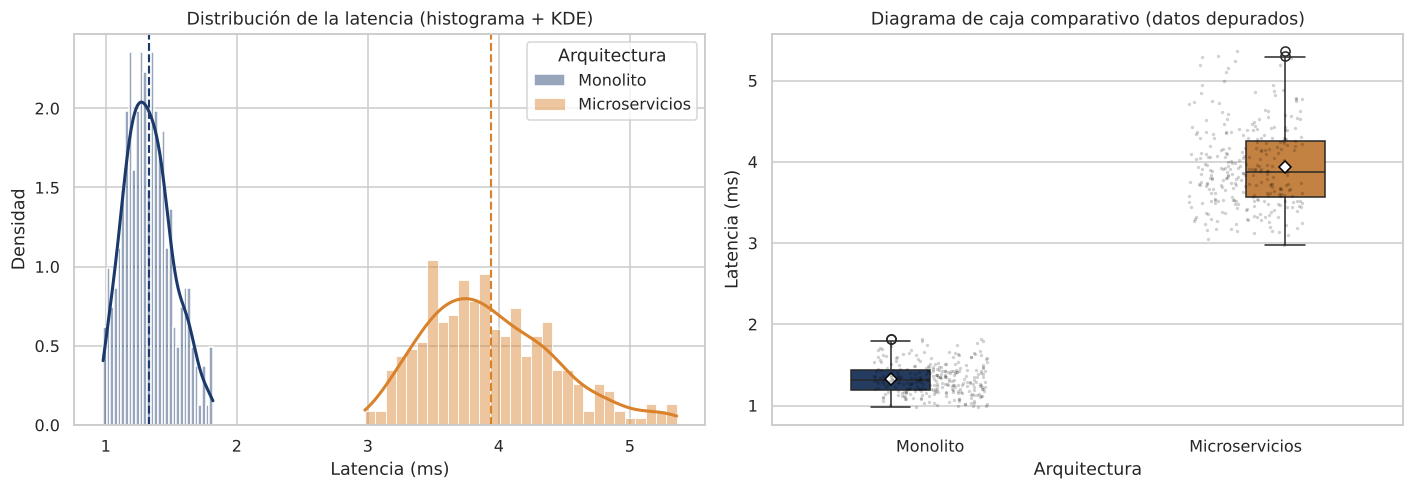

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))

for g in GRUPOS:
    sns.histplot(df[df["grupo"] == g], x="latencia_ms", kde=True, stat="density", bins=30,
                 color=COLORES[g], alpha=0.45, label=g, ax=ax[0], line_kws={"linewidth": 2})
    ax[0].axvline(df.loc[df["grupo"] == g, "latencia_ms"].mean(), color=COLORES[g], ls="--", lw=1.4)
ax[0].set(title="Distribución de la latencia (histograma + KDE)", xlabel="Latencia (ms)", ylabel="Densidad")
ax[0].legend(title="Arquitectura")

sns.boxplot(data=df, x="grupo", y="latencia_ms", hue="grupo", palette=COLORES, width=0.5,
            ax=ax[1], legend=False, showmeans=True,
            meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black"})
sns.stripplot(data=df, x="grupo", y="latencia_ms", color="black", alpha=0.18, size=2.2, jitter=0.18, ax=ax[1])
ax[1].set(title="Diagrama de caja comparativo (datos depurados)", xlabel="Arquitectura", ylabel="Latencia (ms)")

plt.tight_layout(); guardar(fig, "b1_hist_kde_boxplot.png"); plt.show()

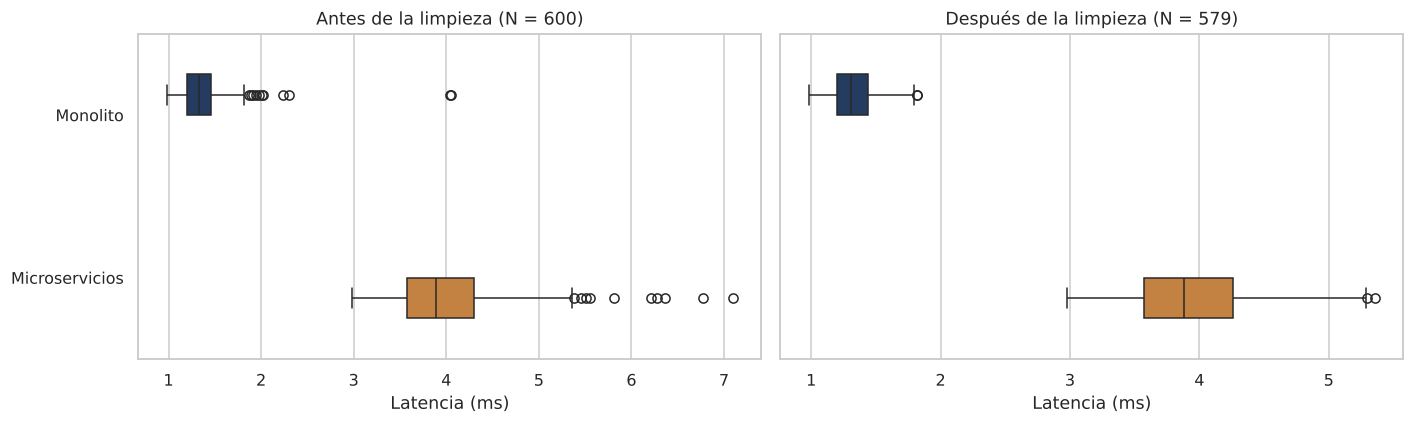

In [8]:
# Boxplot ANTES vs DESPUÉS para evidenciar el efecto de la limpieza
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for a, data, t in [(ax[0], df_raw, "Antes de la limpieza (N = 600)"), (ax[1], df, f"Después de la limpieza (N = {len(df)})")]:
    sns.boxplot(data=data, y="grupo", x="latencia_ms", hue="grupo", palette=COLORES, ax=a, legend=False, width=0.5)
    a.set(title=t, xlabel="Latencia (ms)", ylabel="")
plt.tight_layout(); guardar(fig, "b1_boxplot_antes_despues.png"); plt.show()

**Interpretación de dispersión y sesgo.**

- **Tendencia central.** El Monolito responde en promedio en $\bar{x} \approx 1.33$ ms, mientras que Microservicios lo hace en $\bar{x} \approx 3.94$ ms: casi **3 veces** más. Las cajas ni siquiera se traslapan: el mínimo de Microservicios supera al máximo del Monolito.
- **Dispersión.** Microservicios no solo es más lento, también es **más variable**: su desviación estándar ($s \approx 0.49$ ms) es unas 2.7 veces la del Monolito ($s \approx 0.18$ ms) y su varianza unas 7 veces mayor. Cada salto HTTP agrega su propia variabilidad (establecimiento de conexión TCP, serialización), y esas varianzas se **suman**. Esto anticipa que la prueba de Levene rechazará la homogeneidad de varianzas.
- **Sesgo.** Ambas distribuciones tienen **asimetría positiva** (cola a la derecha; asimetría ≈ 0.61 en Microservicios y ≈ 0.41 en Monolito), lo cual es típico de las latencias: existe un piso físico (no puede bajar de cierto tiempo mínimo) pero sí puede haber picos ocasionales. La media queda ligeramente por encima de la mediana en ambos grupos.
- **Curtosis.** El exceso de curtosis es cercano a 0 (≈ 0.03 y ≈ −0.29), es decir, tras la limpieza las colas son similares a las de una normal; la remoción de atípicos eliminó las colas pesadas visibles en el boxplot "antes".

---
# Bloque 2 · Distribuciones de muestreo y Teorema Central del Límite
### 2.1 Muestra global de la métrica
Se aísla la latencia de **todas** las peticiones depuradas ($N \geq 400$). Esta "población" es deliberadamente **no normal**: al mezclar ambas arquitecturas es **bimodal** (dos picos), lo que la convierte en una prueba exigente del TCL.

N = 579 | media = 2.6348 ms | s = 1.3577 ms | asimetría = 0.1754 | curtosis = -1.6537
Shapiro-Wilk de la muestra global: p = 4.929e-24 → NO es normal


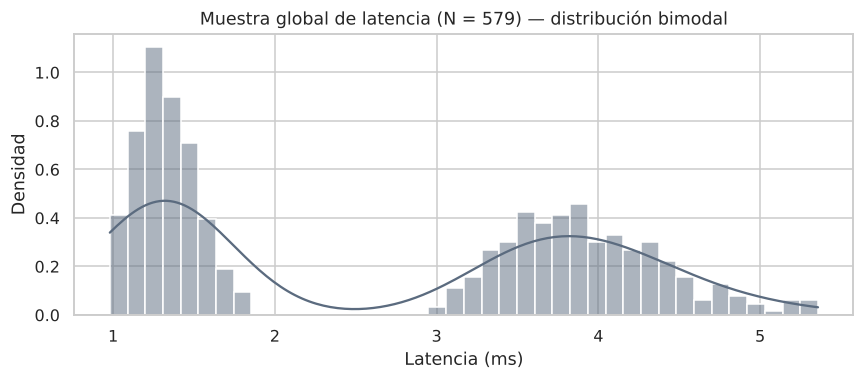

In [9]:
global_lat = df["latencia_ms"].to_numpy()
N = global_lat.size
mu_g, s_g = global_lat.mean(), global_lat.std(ddof=1)
print(f"N = {N} | media = {mu_g:.4f} ms | s = {s_g:.4f} ms | "
      f"asimetría = {stats.skew(global_lat, bias=False):.4f} | curtosis = {stats.kurtosis(global_lat, bias=False):.4f}")
print("Shapiro-Wilk de la muestra global: p =", f"{stats.shapiro(global_lat).pvalue:.3e}", "→ NO es normal")

fig, ax = plt.subplots(figsize=(8, 3.6))
sns.histplot(global_lat, bins=40, kde=True, stat="density", color="#5B6B7F", ax=ax)
ax.set(title=f"Muestra global de latencia (N = {N}) — distribución bimodal", xlabel="Latencia (ms)", ylabel="Densidad")
plt.tight_layout(); guardar(fig, "b2_poblacion_global.png"); plt.show()

### 2.2 Remuestreo con reemplazo ($k = 1000$, $n \in \{5, 15, 30, 60\}$)

In [10]:
TAMANOS = (5, 15, 30, 60)
K = 1000
medias = simular_tcl(global_lat, TAMANOS, K, rng=np.random.default_rng(SEMILLA))
{n: m[:5].round(4) for n, m in medias.items()}

{5: array([2.6637, 1.8563, 3.5929, 1.7472, 2.5472]),
 15: array([2.3392, 2.6975, 3.2271, 2.5509, 2.8871]),
 30: array([2.864 , 2.4464, 2.8169, 2.9126, 2.527 ]),
 60: array([2.4109, 2.3381, 2.5624, 2.4902, 2.8485])}

### 2.3 Cuadrícula 2 × 2 de las distribuciones de medias muestrales

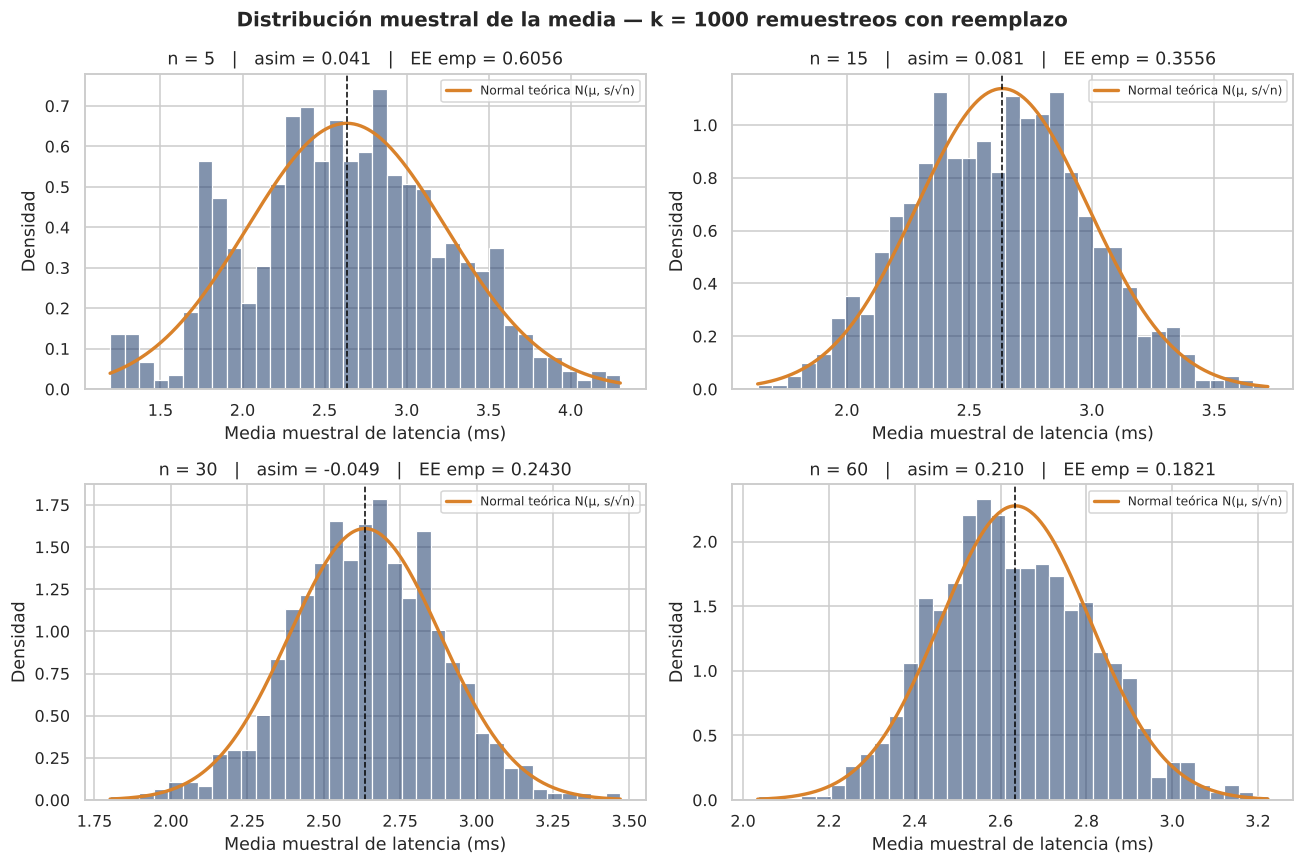

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, n in zip(axes.ravel(), TAMANOS):
    m = medias[n]
    ee_teo = s_g / np.sqrt(n)
    sns.histplot(m, bins=35, stat="density", color="#1B3A6B", alpha=0.55, ax=ax, edgecolor="white")
    x = np.linspace(m.min(), m.max(), 300)
    ax.plot(x, stats.norm.pdf(x, mu_g, ee_teo), color="#D9822B", lw=2.2, label="Normal teórica N(μ, s/√n)")
    ax.axvline(mu_g, color="black", ls="--", lw=1)
    ax.set(title=f"n = {n}   |   asim = {stats.skew(m):.3f}   |   EE emp = {m.std(ddof=1):.4f}",
           xlabel="Media muestral de latencia (ms)", ylabel="Densidad")
    ax.legend(fontsize=8, loc="upper right")
fig.suptitle(f"Distribución muestral de la media — k = {K} remuestreos con reemplazo", fontsize=13, weight="bold")
plt.tight_layout(); guardar(fig, "b2_tcl_grid.png"); plt.show()

### 2.4 Error estándar empírico vs. teórico $\sigma_{\bar{x}} = s/\sqrt{n}$

In [12]:
filas = []
for n in TAMANOS:
    m = medias[n]
    ee_emp = m.std(ddof=1)
    ee_teo = s_g / np.sqrt(n)
    filas.append({"n": n, "media de medias": m.mean(), "EE empírico": ee_emp, "EE teórico s/√n": ee_teo,
                  "error relativo %": 100 * abs(ee_emp - ee_teo) / ee_teo,
                  "asimetría": stats.skew(m), "curtosis (exceso)": stats.kurtosis(m),
                  "Shapiro p": stats.shapiro(m).pvalue})
tabla_tcl = pd.DataFrame(filas).set_index("n")
tabla_tcl

,media de medias,EE empírico,EE teórico s/√n,error relativo %,asimetría,curtosis (exceso),Shapiro p
n,,,,,,,
5,2.6288,0.6056,0.6072,0.2632,0.0408,-0.3658,0.0013
15,2.6243,0.3556,0.3505,1.4397,0.0807,-0.3592,0.0167
30,2.6387,0.2430,0.2479,1.9685,-0.0494,0.2616,0.3284
60,2.6316,0.1821,0.1753,3.8990,0.2099,-0.1630,0.0043


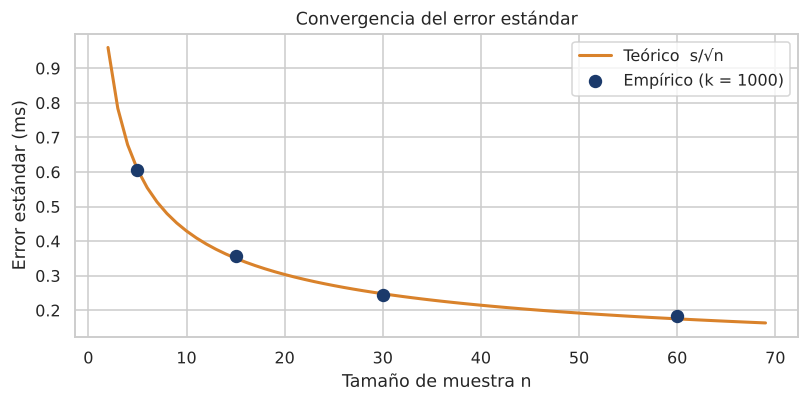

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
nn = np.arange(2, 70)
ax.plot(nn, s_g / np.sqrt(nn), color="#D9822B", lw=2, label="Teórico  s/√n")
ax.scatter(tabla_tcl.index, tabla_tcl["EE empírico"], color="#1B3A6B", s=60, zorder=3, label="Empírico (k = 1000)")
ax.set(title="Convergencia del error estándar", xlabel="Tamaño de muestra n", ylabel="Error estándar (ms)")
ax.legend(); plt.tight_layout(); guardar(fig, "b2_error_estandar.png"); plt.show()

**Justificación de la convergencia a la normalidad.**

1. **Centro.** En los cuatro tamaños, la media de las 1000 medias coincide con la media global ($\mu \approx 2.63$ ms): $\bar{x}$ es un estimador **insesgado** de $\mu$.
2. **Dispersión.** El error estándar empírico coincide con el teórico $s/\sqrt{n}$ con un error relativo de pocos puntos porcentuales, y **disminuye proporcionalmente a $1/\sqrt{n}$**: al cuadruplicar $n$ (15 → 60) el EE se reduce a la mitad. Las pequeñas discrepancias se deben a que $k = 1000$ es finito.
3. **Forma.** Aunque la población es bimodal y nada normal (Shapiro $p \approx 5\times10^{-24}$), desde $n = 5$ la distribución de medias ya es **unimodal y simétrica**, y para todos los tamaños la asimetría y el exceso de curtosis de las medias quedan en $|\cdot| < 0.4$, valores propios de una normal; el histograma se ajusta cada vez mejor a la curva teórica conforme crece $n$. La prueba de Shapiro-Wilk sobre las 1000 medias rechaza la normalidad en algunos tamaños, pero con $k = 1000$ esa prueba es extremadamente sensible y detecta desviaciones mínimas sin relevancia práctica; por eso la evaluación se basa en la forma, la asimetría y la curtosis, no solo en el *p-value*.

Esto es exactamente lo que predice el **Teorema Central del Límite**: $\bar{X} \;\dot\sim\; N\!\left(\mu,\ \sigma/\sqrt{n}\right)$ para $n$ suficientemente grande, sin importar la forma de la población. Es la base que **justifica** los intervalos t y la prueba t de los bloques siguientes, aun cuando las latencias individuales tienen sesgo.

---
# Bloque 3 · Estimación por intervalos de confianza
### 3.1 IC para la media poblacional general $\mu$ al 90 %, 95 % y 99 %

**Selección de la distribución.** La desviación estándar poblacional $\sigma$ es **desconocida** (solo tenemos $s$), por lo que el estadístico $\dfrac{\bar{X}-\mu}{s/\sqrt{n}}$ sigue una **t-Student con $n-1$ grados de libertad**. Se usa entonces:

$$\bar{x} \pm t_{\alpha/2,\,n-1}\,\frac{s}{\sqrt{n}}$$

Con $n = 579$ los grados de libertad son tantos que $t \approx Z$; por eso se reporta también el IC con $Z$ como comparación: la diferencia aparece solo en la cuarta cifra decimal. La t es la elección formalmente correcta y, además, la conservadora (intervalos ligeramente más anchos). La validez de ambos se apoya en el TCL (Bloque 2).

In [14]:
tabla_ic = pd.DataFrame([ic_media(global_lat, c) for c in (0.90, 0.95, 0.99)]).set_index("confianza")
tabla_ic

,n,media,EE,t_crit,LI_t,LS_t,z_crit,LI_z,LS_z,margen_t
confianza,,,,,,,,,,
90%,579,2.6348,0.0564,1.6475,2.5418,2.7277,1.6449,2.5419,2.7276,0.0930
95%,579,2.6348,0.0564,1.9641,2.5239,2.7456,1.9600,2.5242,2.7453,0.1108
99%,579,2.6348,0.0564,2.5844,2.4889,2.7806,2.5758,2.4894,2.7801,0.1458


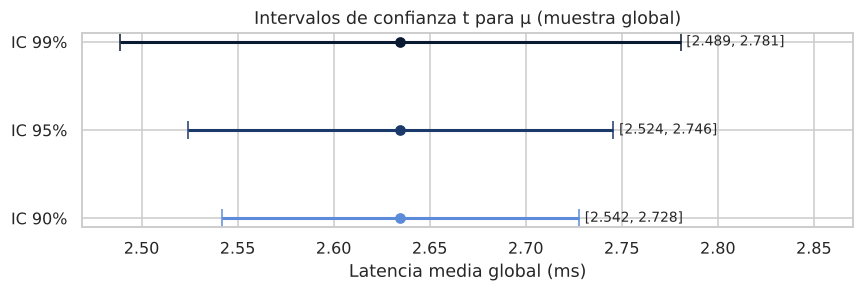

In [15]:
fig, ax = plt.subplots(figsize=(8, 2.8))
for i, (conf, r) in enumerate(tabla_ic.iterrows()):
    ax.errorbar(r["media"], i, xerr=r["margen_t"], fmt="o", capsize=6, lw=2, color=["#5B8BD9", "#1B3A6B", "#0B1A33"][i])
    ax.text(r["LS_t"] + 0.003, i, f"[{r['LI_t']:.3f}, {r['LS_t']:.3f}]", va="center", fontsize=9)
ax.set_yticks(range(3), [f"IC {c}" for c in tabla_ic.index])
ax.set(xlabel="Latencia media global (ms)", title="Intervalos de confianza t para μ (muestra global)")
ax.set_xlim(tabla_ic["LI_t"].min() - 0.02, tabla_ic["LS_t"].max() + 0.09)
plt.tight_layout(); guardar(fig, "b3_ic_media.png"); plt.show()

**Interpretación.** Con 95 % de confianza, la latencia media del sistema (ambas arquitecturas mezcladas) está entre los límites del IC 95 %. A mayor confianza el intervalo se ensancha (el $t$ crítico crece de ≈ 1.65 a ≈ 2.58): **más confianza implica menos precisión**. Cabe advertir que esta media global mezcla dos poblaciones distintas, así que su utilidad práctica es limitada; el intervalo realmente relevante para la decisión es el de la **diferencia** de medias.

### 3.2 IC del 95 % para la diferencia de medias $\mu_1 - \mu_2$
Se define $\mu_1$ = latencia media de **Microservicios** y $\mu_2$ = latencia media del **Monolito**, de modo que una diferencia positiva representa la penalización de latencia de los microservicios.

**Paso 1 — Prueba de Levene** (homogeneidad de varianzas):
$H_0: \sigma_1^2 = \sigma_2^2$ vs. $H_1: \sigma_1^2 \neq \sigma_2^2$, con $\alpha = 0.05$. Se usa `center="median"` (variante de Brown-Forsythe, la predeterminada en SciPy), robusta ante el sesgo observado en el Bloque 1.

In [16]:
micro = df.loc[df["grupo"] == "Microservicios", "latencia_ms"].to_numpy()
mono = df.loc[df["grupo"] == "Monolito", "latencia_ms"].to_numpy()

lev = stats.levene(micro, mono, center="median")
varianzas_iguales = lev.pvalue >= ALFA
print(f"Levene: W = {lev.statistic:.4f}, p-value = {lev.pvalue:.3e}")
print("Decisión:", "No se rechaza H0 → varianzas homogéneas → IC con varianza combinada"
      if varianzas_iguales else "Se rechaza H0 → varianzas DIFERENTES → IC con corrección de Welch")

Levene: W = 165.3304, p-value = 1.891e-33
Decisión: Se rechaza H0 → varianzas DIFERENTES → IC con corrección de Welch


**Paso 2 — Cálculo del intervalo adecuado.**

In [17]:
ic_dif = ic_diferencia(micro, mono, 0.95, varianzas_iguales=varianzas_iguales)
ic_pooled = ic_diferencia(micro, mono, 0.95, varianzas_iguales=True)   # solo como comparación

ci_scipy = stats.ttest_ind(micro, mono, equal_var=varianzas_iguales).confidence_interval(0.95)

pd.DataFrame([ic_dif, ic_pooled]).set_index("método").assign(
    SciPy_LI=[ci_scipy.low, np.nan], SciPy_LS=[ci_scipy.high, np.nan])

,diferencia,EE,gl,t_crit,LI,LS,SciPy_LI,SciPy_LS
método,,,,,,,,
Welch-Satterthwaite,2.6094,0.0309,368.1270,1.9664,2.5487,2.6701,2.5487,2.6701
Varianza combinada (pooled),2.6094,0.0309,577.0000,1.9641,2.5487,2.6701,NaN,NaN


La fórmula aplicada (Welch) es:

$$(\bar{x}_1-\bar{x}_2) \pm t_{\alpha/2,\,\nu}\sqrt{\frac{s_1^2}{n_1}+\frac{s_2^2}{n_2}} \qquad \nu=\frac{\left(\frac{s_1^2}{n_1}+\frac{s_2^2}{n_2}\right)^2}{\frac{(s_1^2/n_1)^2}{n_1-1}+\frac{(s_2^2/n_2)^2}{n_2-1}}$$

Los límites calculados manualmente coinciden con los de `scipy.stats.ttest_ind(...).confidence_interval()`, lo que valida la implementación.

### 3.3 ¿Pertenece el cero al intervalo?

IC 95 % para μ_micro − μ_mono: [2.5487, 2.6701] ms
¿0 ∈ IC? NO
Penalización relativa estimada: entre +192 % y +201 % sobre la latencia del monolito
Costo por salto HTTP (3 saltos): ≈ 0.870 ms


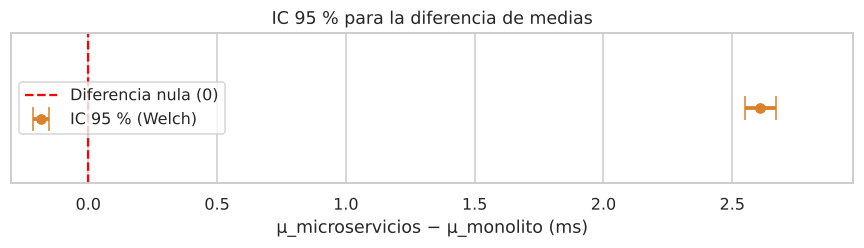

In [18]:
cero_en_ic = ic_dif["LI"] <= 0 <= ic_dif["LS"]
print(f"IC 95 % para μ_micro − μ_mono: [{ic_dif['LI']:.4f}, {ic_dif['LS']:.4f}] ms")
print("¿0 ∈ IC?", "SÍ" if cero_en_ic else "NO")
print(f"Penalización relativa estimada: entre +{ic_dif['LI'] / mono.mean() * 100:.0f} % y "
      f"+{ic_dif['LS'] / mono.mean() * 100:.0f} % sobre la latencia del monolito")
print(f"Costo por salto HTTP (3 saltos): ≈ {ic_dif['diferencia'] / 3:.3f} ms")

fig, ax = plt.subplots(figsize=(8, 2.4))
ax.errorbar(ic_dif["diferencia"], 0, xerr=[[ic_dif["diferencia"] - ic_dif["LI"]], [ic_dif["LS"] - ic_dif["diferencia"]]],
            fmt="o", capsize=8, lw=2.5, color="#D9822B", label="IC 95 % (Welch)")
ax.axvline(0, color="red", ls="--", lw=1.5, label="Diferencia nula (0)")
ax.set_yticks([]); ax.set_xlim(-0.3, ic_dif["LS"] + 0.3)
ax.set(xlabel="μ_microservicios − μ_monolito (ms)", title="IC 95 % para la diferencia de medias")
ax.legend(loc="center left"); plt.tight_layout(); guardar(fig, "b3_ic_diferencia.png"); plt.show()

**Impacto práctico.** El cero **no** pertenece al intervalo; de hecho, el intervalo completo está muy alejado del cero y es estrecho (alrededor de ±0.06 ms). Esto significa que:

- Con 95 % de confianza, **la diferencia real no es nula**: la arquitectura de microservicios es más lenta, y no por azar.
- La magnitud es **acotada con precisión**: los microservicios añaden entre ≈ 2.55 y ≈ 2.67 ms por petición, es decir, cerca de **0.87 ms por cada salto HTTP** entre servicios. En términos relativos la latencia casi se **triplica** (+192 % a +201 %).
- Como todo el intervalo es positivo, el IC ya anticipa el resultado de la prueba de hipótesis del Bloque 4: la dualidad IC–prueba garantiza que un contraste bilateral con $\alpha = 0.05$ rechazará $H_0: \mu_1 = \mu_2$.

---
# Bloque 4 · Teoría de decisión estadística (prueba de hipótesis)
### 4.1 Planteamiento de hipótesis
El problema pregunta si la sobrecarga de red **incrementa** la latencia, por lo que la hipótesis de investigación es **direccional** (prueba de cola derecha):

$$H_0:\ \mu_{\text{micro}} \le \mu_{\text{mono}} \quad \text{(los microservicios NO incrementan la latencia)}$$
$$H_1:\ \mu_{\text{micro}} > \mu_{\text{mono}} \quad \text{(los microservicios SÍ incrementan la latencia)}$$

### 4.2 Matriz de decisión y costos de los errores

| Decisión \ Realidad | $H_0$ verdadera (no hay penalización) | $H_0$ falsa (sí hay penalización) |
|---|---|---|
| **Rechazar $H_0$** | ❌ **Error Tipo I** ($\alpha$) | ✅ Decisión correcta (potencia $1-\beta$) |
| **No rechazar $H_0$** | ✅ Decisión correcta ($1-\alpha$) | ❌ **Error Tipo II** ($\beta$) |

**Costo del Error Tipo I** (*concluir que hay penalización cuando no la hay*): el equipo descartaría injustificadamente los microservicios —perdiendo escalabilidad independiente, despliegues aislados y tolerancia a fallos— o invertiría horas de ingeniería y presupuesto en optimizaciones innecesarias (migrar a gRPC, *service mesh*, cachés distribuidas) para resolver un problema inexistente.

**Costo del Error Tipo II** (*no detectar una penalización real*): se migraría a microservicios asumiendo que la latencia no cambia. En producción, cada salto adicional se acumula a lo largo de cadenas de llamadas; se violarían los acuerdos de nivel de servicio (SLA/SLO), se degradaría la experiencia de usuario y el costo de revertir la arquitectura sería muy alto. En este contexto **el Error Tipo II es el más costoso**, por lo que interesa una prueba con alta potencia; el tamaño de muestra grande ($n \approx 290$ por grupo) la garantiza (ver 4.5).

### 4.3 Nivel de significancia

In [19]:
print(f"α = {ALFA}  →  se acepta un 5 % de riesgo de cometer Error Tipo I")
print(f"Valor crítico (cola derecha, Welch): t_crit = {stats.t.ppf(1 - ALFA, ic_dif['gl']):.4f} con ν ≈ {ic_dif['gl']:.1f} gl")

α = 0.05  →  se acepta un 5 % de riesgo de cometer Error Tipo I
Valor crítico (cola derecha, Welch): t_crit = 1.6490 con ν ≈ 368.1 gl


### 4.4 Ejecución de la prueba paramétrica (`scipy.stats.ttest_ind`)
Dado que Levene rechazó la igualdad de varianzas, se usa la **prueba t de Welch** (`equal_var=False`) con `alternative="greater"`. El supuesto de normalidad de las medias está respaldado por el TCL (Bloque 2) y por los tamaños muestrales grandes.

In [20]:
prueba = stats.ttest_ind(micro, mono, equal_var=varianzas_iguales, alternative="greater")
prueba_bilateral = stats.ttest_ind(micro, mono, equal_var=varianzas_iguales)

# Tamaño del efecto (d de Cohen con desviación combinada)
sp = np.sqrt(((micro.size - 1) * micro.var(ddof=1) + (mono.size - 1) * mono.var(ddof=1)) / (micro.size + mono.size - 2))
d_cohen = (micro.mean() - mono.mean()) / sp

mw = stats.mannwhitneyu(micro, mono, alternative="greater")

resultado = pd.Series({
    "Estadístico t (Welch)": prueba.statistic,
    "Grados de libertad ν": prueba.df,
    "p-value (unilateral, cola derecha)": prueba.pvalue,
    "p-value (bilateral)": prueba_bilateral.pvalue,
    "t crítico (α = 0.05, una cola)": stats.t.ppf(1 - ALFA, prueba.df),
    "d de Cohen": d_cohen,
    "Mann-Whitney U (respaldo) p-value": mw.pvalue,
}, name="valor")
resultado.to_frame().style.format("{:.4g}")

,valor
Estadístico t (Welch),84.52
Grados de libertad ν,368.1
"p-value (unilateral, cola derecha)",1.752e-243
p-value (bilateral),3.504e-243
"t crítico (α = 0.05, una cola)",1.649
d de Cohen,7.016
Mann-Whitney U (respaldo) p-value,1.414e-96


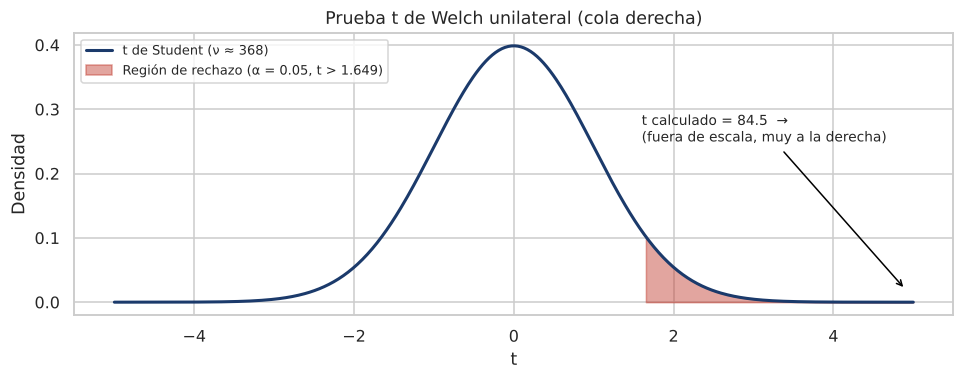

In [21]:
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.linspace(-5, 5, 500)
ax.plot(x, stats.t.pdf(x, prueba.df), color="#1B3A6B", lw=2, label=f"t de Student (ν ≈ {prueba.df:.0f})")
tc = stats.t.ppf(1 - ALFA, prueba.df)
ax.fill_between(x[x >= tc], stats.t.pdf(x[x >= tc], prueba.df), color="#C0392B", alpha=0.45,
                label=f"Región de rechazo (α = 0.05, t > {tc:.3f})")
ax.annotate(f"t calculado = {prueba.statistic:.1f}  →\n(fuera de escala, muy a la derecha)",
            xy=(4.9, 0.02), xytext=(1.6, 0.25), fontsize=9, ha="left",
            arrowprops=dict(arrowstyle="->", color="black"))
ax.set(title="Prueba t de Welch unilateral (cola derecha)", xlabel="t", ylabel="Densidad")
ax.legend(loc="upper left", fontsize=8.5); plt.tight_layout(); guardar(fig, "b4_region_rechazo.png"); plt.show()

### 4.5 Riesgo de Error Tipo II ($\beta$) y potencia
Para cuantificar $\beta$ se calcula la potencia de la prueba para detectar diferencias **de interés práctico** (de 0.05 a 0.5 ms), usando la distribución t no central.

In [22]:
def potencia_welch(delta, s1, s2, n1, n2, alfa=ALFA):
    ee = np.sqrt(s1**2 / n1 + s2**2 / n2)
    gl = (s1**2 / n1 + s2**2 / n2) ** 2 / ((s1**2 / n1) ** 2 / (n1 - 1) + (s2**2 / n2) ** 2 / (n2 - 1))
    tc = stats.t.ppf(1 - alfa, gl)
    return 1 - stats.nct.cdf(tc, gl, delta / ee)

s1, s2 = micro.std(ddof=1), mono.std(ddof=1)
tabla_pot = pd.DataFrame([{"Δ a detectar (ms)": d,
                           "Potencia (1-β)": potencia_welch(d, s1, s2, micro.size, mono.size),
                           "β (riesgo Tipo II)": 1 - potencia_welch(d, s1, s2, micro.size, mono.size)}
                          for d in (0.05, 0.10, 0.25, 0.50, ic_dif["diferencia"])]).set_index("Δ a detectar (ms)")
tabla_pot

,Potencia (1-β),β (riesgo Tipo II)
Δ a detectar (ms),,
0.0500,0.4887,0.5113
0.1000,0.9439,0.0561
0.2500,1.0000,0.0000
0.5000,1.0000,0.0000
2.6094,1.0000,0.0000


Con este diseño la prueba detectaría una penalización de apenas 0.10 ms con probabilidad ≈ 0.94 ($\beta \approx 0.06$), y cualquiera de 0.25 ms o más con probabilidad prácticamente 1; solo diferencias minúsculas (≈ 0.05 ms, irrelevantes para un usuario) tendrían un riesgo alto de pasar inadvertidas. para la diferencia observada ($\approx$ 2.6 ms) la potencia es prácticamente 1 y $\beta \approx 0$. El riesgo de cometer el error más costoso (Tipo II) está, por tanto, controlado.

### 4.6 Veredicto formal y recomendación técnica

In [23]:
rechazar = prueba.pvalue < ALFA
print("=" * 78)
print(f"t = {prueba.statistic:.4f}   ν = {prueba.df:.2f}   p-value = {prueba.pvalue:.3e}   α = {ALFA}")
print("VEREDICTO:", "SE RECHAZA H0" if rechazar else "NO SE RECHAZA H0")
print("=" * 78)
print(f"Latencia media Microservicios: {micro.mean():.3f} ms  |  Monolito: {mono.mean():.3f} ms")
print(f"Diferencia estimada: {micro.mean() - mono.mean():.3f} ms  IC95% [{ic_dif['LI']:.3f}, {ic_dif['LS']:.3f}]")

t = 84.5249   ν = 368.13   p-value = 1.752e-243   α = 0.05
VEREDICTO: SE RECHAZA H0
Latencia media Microservicios: 3.937 ms  |  Monolito: 1.328 ms
Diferencia estimada: 2.609 ms  IC95% [2.549, 2.670]


**Veredicto.** Como $p \approx 10^{-243} < \alpha = 0.05$ (y $t \approx 84.5$ supera ampliamente el valor crítico ≈ 1.65), **se rechaza $H_0$**. Existe evidencia estadísticamente significativa de que la arquitectura de microservicios **incrementa** la latencia de respuesta respecto al monolito. El resultado es consistente con el IC del Bloque 3 (0 ∉ IC), con la prueba no paramétrica de Mann-Whitney ($p \approx 10^{-96}$) y con un tamaño del efecto enorme ($d$ de Cohen ≈ 7.0, cuando 0.8 ya se considera "grande"), por lo que la conclusión no depende de los supuestos de normalidad.

**Recomendación técnica de ingeniería.**

1. **Para rutas críticas en latencia** (p. ej., autenticación, *checkout*, APIs de tiempo real) se recomienda **mantener la lógica en un monolito o en un único servicio**, pues la descomposición le añade ≈ 2.6 ms por petición (≈ 0.87 ms por salto) **incluso en *loopback***. En una red real (LAN/nube, con TLS y *balanceadores*) cada salto suele costar más, por lo que la penalización observada es un **límite inferior**.
2. **Si la organización necesita microservicios** (escalado independiente, equipos autónomos, despliegues aislados), la penalización debe **mitigarse** y presupuestarse en el SLO:
   - Reutilizar conexiones (*keep-alive* / *connection pooling*) en lugar de abrir una conexión TCP por llamada.
   - Paralelizar las llamadas independientes en el *gateway* (`usuarios` e `inventario` no dependen entre sí) con `asyncio`/hilos.
   - Usar protocolos binarios (gRPC/Protocol Buffers) en lugar de JSON sobre HTTP/1.1.
   - Aplicar el patrón *Backend for Frontend* o agregar datos con caché para reducir saltos en la ruta crítica.
3. **Arquitectura híbrida**: un "monolito modular" para el núcleo transaccional y microservicios solo para los dominios que realmente se beneficien del escalado independiente.

**Limitaciones del estudio.** Las mediciones se tomaron en una sola máquina (comunicación por *loopback*), con carga secuencial y una lógica de negocio sintética; los valores absolutos no son extrapolables a producción, aunque la dirección del efecto sí lo es. Un estudio futuro debería repetir la prueba con concurrencia (Locust/Apache Bench), sobre red física y midiendo percentiles altos (p95/p99).